# UCI HAR : classification d'activite (adaptation inter-sujet)

on classe l'activite (6 classes : marche, montee, descente, assis, debout, couche) a partir des 561 features fournies par le dataset. le decoupage d'UCI HAR separe deja les sujets (21 en train, 9 en test), donc source = sujets d'entrainement, cible = sujets de test.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from adapt_utils import predict, split_har, courbe_apprentissage, courbe_melange, comparer_adapt, barres_adapt, default_model
from collections import Counter


/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## chargement

In [2]:
data_dir = "../../data/UCI HAR Dataset"

Xs = np.loadtxt(f"{data_dir}/train/X_train.txt")
ys = np.loadtxt(f"{data_dir}/train/y_train.txt").astype(int)
subj_s = np.loadtxt(f"{data_dir}/train/subject_train.txt").astype(int)

Xt = np.loadtxt(f"{data_dir}/test/X_test.txt")
yt = np.loadtxt(f"{data_dir}/test/y_test.txt").astype(int)
subj_t = np.loadtxt(f"{data_dir}/test/subject_test.txt").astype(int)

Xs.shape, Xt.shape, sorted(set(ys))

((7352, 561),
 (2947, 561),
 [np.int64(1),
  np.int64(2),
  np.int64(3),
  np.int64(4),
  np.int64(5),
  np.int64(6)])

## tableaux utilises

le dataset fournit six tableaux, trois pour la source et trois pour la cible : la matrice des 561 features, l'activite a predire, et l'identifiant du sujet. 

les trois tableaux d'un meme domaine sont alignes ligne a ligne, une ligne etant une fenetre de 2.56 secondes.

In [3]:
noms_features = [l.split(" ", 1)[1] for l in open(f"{data_dir}/features.txt").read().strip().split("\n")]
activites = dict(l.split() for l in open(f"{data_dir}/activity_labels.txt").read().strip().split("\n"))

resume = pd.DataFrame([
    ["Xs", Xs.shape, "features source (21 sujets)"],
    ["ys", ys.shape, "activite source"],
    ["subj_s", subj_s.shape, "sujet source"],
    ["Xt", Xt.shape, "features cible (9 sujets)"],
    ["yt", yt.shape, "activite cible"],
    ["subj_t", subj_t.shape, "sujet cible"],
], columns=["tableau", "dimensions", "contenu"])
print(resume.to_string(index=False))
print()
print("activites :", activites)

tableau  dimensions                     contenu
     Xs (7352, 561) features source (21 sujets)
     ys     (7352,)             activite source
 subj_s     (7352,)                sujet source
     Xt (2947, 561)   features cible (9 sujets)
     yt     (2947,)              activite cible
 subj_t     (2947,)                 sujet cible

activites : {'1': 'WALKING', '2': 'WALKING_UPSTAIRS', '3': 'WALKING_DOWNSTAIRS', '4': 'SITTING', '5': 'STANDING', '6': 'LAYING'}


In [4]:
apercu = pd.DataFrame(Xs[:5], columns=noms_features)
apercu.insert(0, "activite", [activites[str(v)] for v in ys[:5]])
apercu.insert(0, "sujet", subj_s[:5])

with pd.option_context("display.max_columns", None):
    display(apercu)

,sujet,activite,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,tBodyAcc-min()-Y,tBodyAcc-min()-Z,tBodyAcc-sma(),tBodyAcc-energy()-X,tBodyAcc-energy()-Y,tBodyAcc-energy()-Z,tBodyAcc-iqr()-X,tBodyAcc-iqr()-Y,tBodyAcc-iqr()-Z,tBodyAcc-entropy()-X,tBodyAcc-entropy()-Y,tBodyAcc-entropy()-Z,"tBodyAcc-arCoeff()-X,1","tBodyAcc-arCoeff()-X,2","tBodyAcc-arCoeff()-X,3","tBodyAcc-arCoeff()-X,4","tBodyAcc-arCoeff()-Y,1","tBodyAcc-arCoeff()-Y,2","tBodyAcc-arCoeff()-Y,3","tBodyAcc-arCoeff()-Y,4","tBodyAcc-arCoeff()-Z,1","tBodyAcc-arCoeff()-Z,2","tBodyAcc-arCoeff()-Z,3","tBodyAcc-arCoeff()-Z,4","tBodyAcc-correlation()-X,Y","tBodyAcc-correlation()-X,Z","tBodyAcc-correlation()-Y,Z",tGravityAcc-mean()-X,tGravityAcc-mean()-Y,tGravityAcc-mean()-Z,tGravityAcc-std()-X,tGravityAcc-std()-Y,tGravityAcc-std()-Z,tGravityAcc-mad()-X,tGravityAcc-mad()-Y,tGravityAcc-mad()-Z,tGravityAcc-max()-X,tGravityAcc-max()-Y,tGravityAcc-max()-Z,tGravityAcc-min()-X,tGravityAcc-min()-Y,tGravityAcc-min()-Z,tGravityAcc-sma(),tGravityAcc-energy()-X,tGravityAcc-energy()-Y,tGravityAcc-energy()-Z,tGravityAcc-iqr()-X,tGravityAcc-iqr()-Y,tGravityAcc-iqr()-Z,tGravityAcc-entropy()-X,tGravityAcc-entropy()-Y,tGravityAcc-entropy()-Z,"tGravityAcc-arCoeff()-X,1","tGravityAcc-arCoeff()-X,2","tGravityAcc-arCoeff()-X,3","tGravityAcc-arCoeff()-X,4","tGravityAcc-arCoeff()-Y,1","tGravityAcc-arCoeff()-Y,2","tGravityAcc-arCoeff()-Y,3","tGravityAcc-arCoeff()-Y,4","tGravityAcc-arCoeff()-Z,1","tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4","tGravityAcc-correlation()-X,Y","tGravityAcc-correlation()-X,Z","tGravityAcc-correlation()-Y,Z",tBodyAccJerk-mean()-X,tBodyAccJerk-mean()-Y,tBodyAccJerk-mean()-Z,tBodyAccJerk-std()-X,tBodyAccJerk-std()-Y,tBodyAccJerk-std()-Z,tBodyAccJerk-mad()-X,tBodyAccJerk-mad()-Y,tBodyAccJerk-mad()-Z,tBodyAccJerk-max()-X,tBodyAccJerk-max()-Y,tBodyAccJerk-max()-Z,tBodyAccJerk-min()-X,tBodyAccJerk-min()-Y,tBodyAccJerk-min()-Z,tBodyAccJerk-sma(),tBodyAccJerk-energy()-X,tBodyAccJerk-energy()-Y,tBodyAccJerk-energy()-Z,tBodyAccJerk-iqr()-X,tBodyAccJerk-iqr()-Y,tBodyAccJerk-iqr()-Z,tBodyAccJerk-entropy()-X,tBodyAccJerk-entropy()-Y,tBodyAccJerk-entropy()-Z,"tBodyAccJerk-arCoeff()-X,1","tBodyAccJerk-arCoeff()-X,2","tBodyAccJerk-arCoeff()-X,3","tBodyAccJerk-arCoeff()-X,4","tBodyAccJerk-arCoeff()-Y,1","tBodyAccJerk-arCoeff()-Y,2","tBodyAccJerk-arCoeff()-Y,3","tBodyAccJerk-arCoeff()-Y,4","tBodyAccJerk-arCoeff()-Z,1","tBodyAccJerk-arCoeff()-Z,2","tBodyAccJerk-arCoeff()-Z,3","tBodyAccJerk-arCoeff()-Z,4","tBodyAccJerk-correlation()-X,Y","tBodyAccJerk-correlation()-X,Z","tBodyAccJerk-correlation()-Y,Z",tBodyGyro-mean()-X,tBodyGyro-mean()-Y,tBodyGyro-mean()-Z,tBodyGyro-std()-X,tBodyGyro-std()-Y,tBodyGyro-std()-Z,tBodyGyro-mad()-X,tBodyGyro-mad()-Y,tBodyGyro-mad()-Z,tBodyGyro-max()-X,tBodyGyro-max()-Y,tBodyGyro-max()-Z,tBodyGyro-min()-X,tBodyGyro-min()-Y,tBodyGyro-min()-Z,tBodyGyro-sma(),tBodyGyro-energy()-X,tBodyGyro-energy()-Y,tBodyGyro-energy()-Z,tBodyGyro-iqr()-X,tBodyGyro-iqr()-Y,tBodyGyro-iqr()-Z,tBodyGyro-entropy()-X,tBodyGyro-entropy()-Y,tBodyGyro-entropy()-Z,"tBodyGyro-arCoeff()-X,1","tBodyGyro-arCoeff()-X,2","tBodyGyro-arCoeff()-X,3","tBodyGyro-arCoeff()-X,4","tBodyGyro-arCoeff()-Y,1","tBodyGyro-arCoeff()-Y,2","tBodyGyro-arCoeff()-Y,3","tBodyGyro-arCoeff()-Y,4","tBodyGyro-arCoeff()-Z,1","tBodyGyro-arCoeff()-Z,2","tBodyGyro-arCoeff()-Z,3","tBodyGyro-arCoeff()-Z,4","tBodyGyro-correlation()-X,Y","tBodyGyro-correlation()-X,Z","tBodyGyro-correlation()-Y,Z",tBodyGyroJerk-mean()-X,tBodyGyroJerk-mean()-Y,tBodyGyroJerk-mean()-Z,tBodyGyroJerk-std()-X,tBodyGyroJerk-std()-Y,tBodyGyroJerk-std()-Z,tBodyGyroJerk-mad()-X,tBodyGyroJerk-mad()-Y,tBodyGyroJerk-mad()-Z,tBodyGyroJerk-max()-X,tBodyGyroJerk-max()-Y,tBodyGyroJerk-max()-Z,tBodyGyroJerk-min()-X,tBodyGyroJerk-min()-Y,tBodyGyroJerk-min

## 1. visualisation


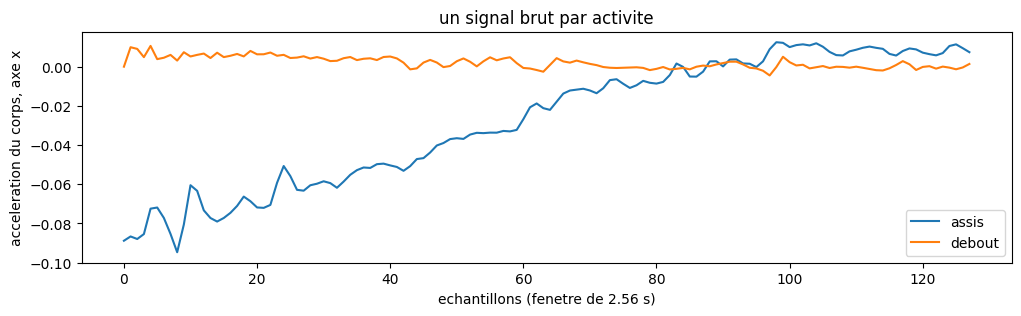

In [5]:
signaux = f"{data_dir}/train/Inertial Signals"
acc_x = np.loadtxt(f"{signaux}/body_acc_x_train.txt")

plt.figure(figsize=(12, 3))
for label, nom in [(4, "assis"), (5, "debout")]:
    idx = np.where(ys == label)[0][0]
    plt.plot(acc_x[idx], label=nom)
plt.xlabel("echantillons (fenetre de 2.56 s)")
plt.ylabel("acceleration du corps, axe x")
plt.title("un signal brut par activite")
plt.legend()
plt.show()

## 2. decoupage par sujet

on decoupe par sujet. les fenetres se recouvrent a 50 pourcent, donc deux fenetres voisines du meme sujet partagent des donnees. on garde 4 sujets source pour le test source, et on separe les 9 sujets cible en 6 pour l'adaptation et 3 pour le test cible.

In [6]:
Xs_train, ys_train, Xs_test, ys_test, Xt_train, yt_train, Xt_test, yt_test = split_har(
    Xs, ys, subj_s, Xt, yt, subj_t)

len(Xs_train), len(Xs_test), len(Xt_train), len(Xt_test)

(5867, 1485, 1848, 1099)

## 3. source vers source et source vers cible

In [7]:
r_source_source = predict("classification", Xs_train, ys_train, Xs_test, ys_test)
r_source_cible = predict("classification", Xs_train, ys_train, Xt_test, yt_test)
r_cible_cible = predict("classification", Xt_train, yt_train, Xt_test, yt_test)

print("source -> source :", round(r_source_source["accuracy"], 3))
print("source -> cible  :", round(r_source_cible["accuracy"], 3))
print("cible  -> cible  :", round(r_cible_cible["accuracy"], 3))

source -> source : 0.966
source -> cible  : 0.969
cible  -> cible  : 0.881


## 4. combien de donnees cible pour un bon modele


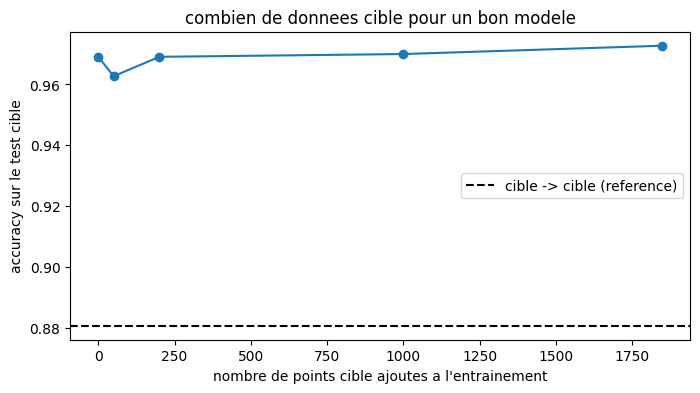

In [8]:
n_values = [0, 50, 200, 1000, len(Xt_train)]
acc_courbe = []
for n in n_values:
    if n == 0:
        X_train, y_train = Xs_train, ys_train
    else:
        X_train = np.vstack([Xs_train, Xt_train[:n]])
        y_train = np.concatenate([ys_train, yt_train[:n]])
    acc_courbe.append(predict("classification", X_train, y_train, Xt_test, yt_test)["accuracy"])

plt.figure(figsize=(8, 4))
plt.plot(n_values, acc_courbe, marker="o")
plt.axhline(r_cible_cible["accuracy"], color="k", linestyle="--", label="cible -> cible (reference)")
plt.xlabel("nombre de points cible ajoutes a l'entrainement")
plt.ylabel("accuracy sur le test cible")
plt.title("combien de donnees cible pour un bon modele")
plt.legend()
plt.show()

## 5. courbes d'apprentissage separees (source et cible)

In [9]:
len(Xs_train)

5867

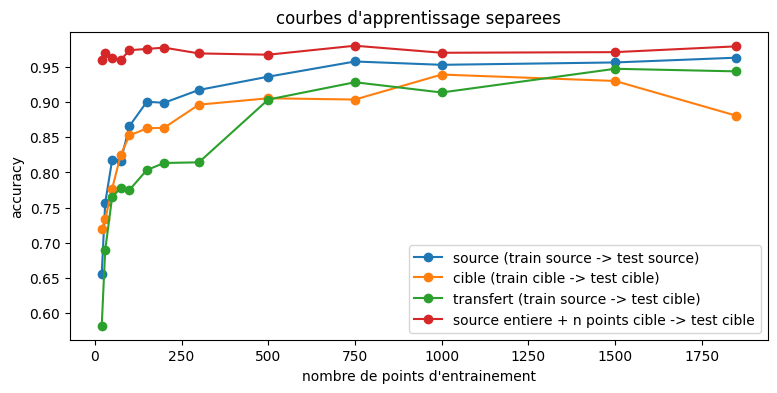

In [10]:
#n_values = [20, 30, 50, 75, 100, 150, 200, 300, 500, 750, 1000, 1500, 1848, 3000, len(Xs_train)]
n_values = [20, 30, 50, 75, 100, 150, 200, 300, 500, 750, 1000, 1500, 1848]
ns_source, acc_source = courbe_apprentissage(Xs_train, ys_train, Xs_test, ys_test, "classification", n_values)
ns_cible, acc_cible = courbe_apprentissage(Xt_train, yt_train, Xt_test, yt_test, "classification", n_values)
ns_transfert, acc_transfert = courbe_apprentissage(Xs_train, ys_train, Xt_test, yt_test, "classification", n_values)
ns_melange, acc_melange = courbe_melange(Xs_train, ys_train, Xt_train, yt_train, Xt_test, yt_test, "classification", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_source, acc_source, marker="o", label="source (train source -> test source)")
plt.plot(ns_cible, acc_cible, marker="o", label="cible (train cible -> test cible)")
plt.plot(ns_transfert, acc_transfert, marker="o", label="transfert (train source -> test cible)")
plt.plot(ns_melange, acc_melange, marker="o", label="source entiere + n points cible -> test cible")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("accuracy")
plt.title("courbes d'apprentissage separees")
plt.legend()
plt.show()

## 6. equilibrage : autant de sujets en source qu'en cible



In [11]:
n_tirages = 5
rng = np.random.default_rng(0)
acc_ss, acc_sc = [], []

for k in range(n_tirages):
    tirage = list(rng.permutation(sorted(set(subj_s)))[:9])
    tr, te = tirage[:6], tirage[6:]
    Xa, ya = Xs[np.isin(subj_s, tr)], ys[np.isin(subj_s, tr)]
    Xb, yb = Xs[np.isin(subj_s, te)], ys[np.isin(subj_s, te)]
    a = predict("classification", Xa, ya, Xb, yb)["accuracy"]
    b = predict("classification", Xa, ya, Xt_test, yt_test)["accuracy"]
    acc_ss.append(a)
    acc_sc.append(b)
    print(f"tirage {k} : {len(Xa)} fenetres   source -> source {a:.3f}   source -> cible {b:.3f}")

print()
print(f"equilibre 9 vs 9, moyenne sur {n_tirages} tirages")
print("  source -> source :", round(float(np.mean(acc_ss)), 3))
print("  source -> cible  :", round(float(np.mean(acc_sc)), 3))
print("  cible  -> cible  :", round(r_cible_cible["accuracy"], 3))

tirage 0 : 2160 fenetres   source -> source 0.875   source -> cible 0.914
tirage 1 : 1984 fenetres   source -> source 0.855   source -> cible 0.924
tirage 2 : 2043 fenetres   source -> source 0.913   source -> cible 0.914
tirage 3 : 2069 fenetres   source -> source 0.903   source -> cible 0.864
tirage 4 : 2052 fenetres   source -> source 0.881   source -> cible 0.908

equilibre 9 vs 9, moyenne sur 5 tirages
  source -> source : 0.885
  source -> cible  : 0.905
  cible  -> cible  : 0.881


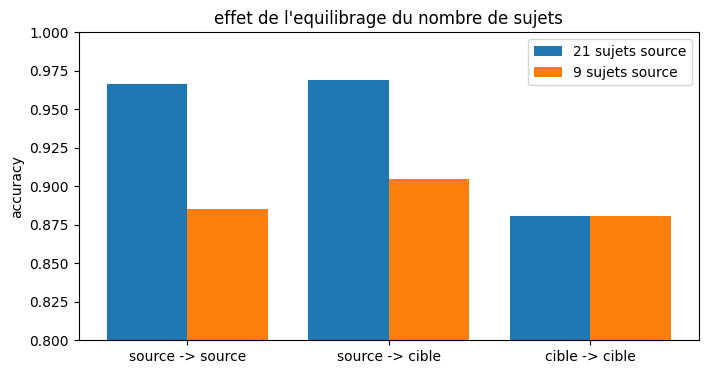

In [12]:
noms = ["source -> source", "source -> cible", "cible -> cible"]
desequilibre = [r_source_source["accuracy"], r_source_cible["accuracy"], r_cible_cible["accuracy"]]
equilibre = [float(np.mean(acc_ss)), float(np.mean(acc_sc)), r_cible_cible["accuracy"]]

x = np.arange(len(noms))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, desequilibre, 0.4, label="21 sujets source")
plt.bar(x + 0.2, equilibre, 0.4, label="9 sujets source")
plt.xticks(x, noms)
plt.ylim(0.8, 1.0)
plt.ylabel("accuracy")
plt.title("effet de l'equilibrage du nombre de sujets")
plt.legend()
plt.show()

source reduite : 2160 fenetres d'entrainement contre 1848 pour la cible


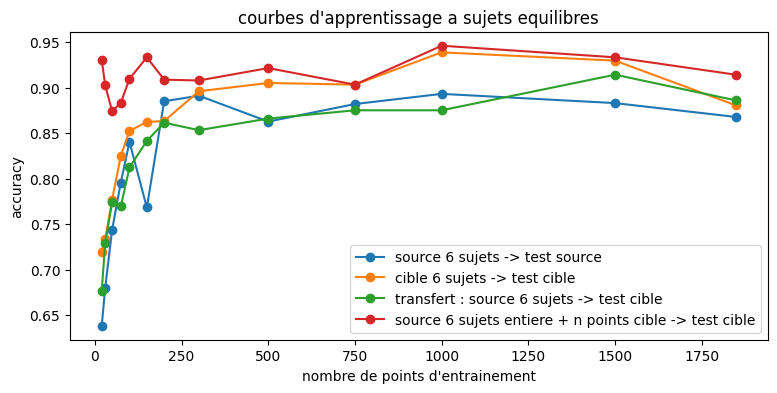

In [13]:
tirage = list(np.random.default_rng(0).permutation(sorted(set(subj_s)))[:9])
Xs9_train, ys9_train = Xs[np.isin(subj_s, tirage[:6])], ys[np.isin(subj_s, tirage[:6])]
Xs9_test, ys9_test = Xs[np.isin(subj_s, tirage[6:])], ys[np.isin(subj_s, tirage[6:])]
print("source reduite :", len(Xs9_train), "fenetres d'entrainement contre", len(Xt_train), "pour la cible")

ns_s9, acc_s9 = courbe_apprentissage(Xs9_train, ys9_train, Xs9_test, ys9_test, "classification", n_values)
ns_c9, acc_c9 = courbe_apprentissage(Xt_train, yt_train, Xt_test, yt_test, "classification", n_values)
ns_t9, acc_t9 = courbe_apprentissage(Xs9_train, ys9_train, Xt_test, yt_test, "classification", n_values)
ns_m9, acc_m9 = courbe_melange(Xs9_train, ys9_train, Xt_train, yt_train, Xt_test, yt_test, "classification", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_s9, acc_s9, marker="o", label="source 6 sujets -> test source")
plt.plot(ns_c9, acc_c9, marker="o", label="cible 6 sujets -> test cible")
plt.plot(ns_t9, acc_t9, marker="o", label="transfert : source 6 sujets -> test cible")
plt.plot(ns_m9, acc_m9, marker="o", label="source 6 sujets entiere + n points cible -> test cible")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("accuracy")
plt.title("courbes d'apprentissage a sujets equilibres")
plt.legend()
plt.show()

## 16. ADAPT

feature_based,CORAL

instance_based, KMM

parameter_based,  RegularTransferLR

(1848, 6)
(1848, 6)
(1848, 6)
(1848, 6)
(1848, 6)
moyenne sur 5 tirages de 6 sujets source
  sans adaptation                  0.905   (de 0.864 a 0.924)
  CORAL (feature)                  0.554   (de 0.413 a 0.766)
  KMM (instance)                   0.872   (de 0.848 a 0.917)
  RegularTransferLC (parametre)    0.934   (de 0.881 a 0.961)
  cible -> cible                   0.881   (de 0.881 a 0.881)


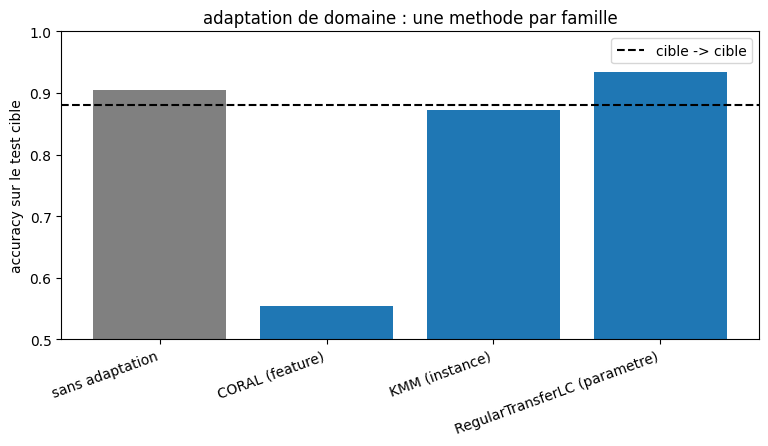

In [14]:
rng_adapt = np.random.default_rng(0)
tables = []
for k in range(n_tirages):
    t = list(rng_adapt.permutation(sorted(set(subj_s)))[:9])
    Xa, ya = Xs[np.isin(subj_s, t[:6])], ys[np.isin(subj_s, t[:6])]
    tables.append(comparer_adapt("classification", Xa, ya, Xt_train, yt_train, Xt_test, yt_test))

resultats = {k: float(np.mean([t[k] for t in tables])) for k in tables[0]}

print(f"moyenne sur {n_tirages} tirages de 6 sujets source")
for k in resultats:
    valeurs = [t[k] for t in tables]
    print(f"  {k:32s} {resultats[k]:.3f}   (de {min(valeurs):.3f} a {max(valeurs):.3f})")

barres_adapt(resultats, "adaptation de domaine : une methode par famille",
             "accuracy sur le test cible", ylim=(0.5, 1.0))

(20, 6)
(50, 6)
(100, 6)
(200, 6)
(300, 6)
(500, 6)
(750, 6)
(1000, 6)
(1500, 6)
(1848, 6)
     20 etiquettes cible : cible seule 0.720   RegularTransferLC 0.731
     50 etiquettes cible : cible seule 0.777   RegularTransferLC 0.677
    100 etiquettes cible : cible seule 0.853   RegularTransferLC 0.626
    200 etiquettes cible : cible seule 0.864   RegularTransferLC 0.600
    300 etiquettes cible : cible seule 0.896   RegularTransferLC 0.593
    500 etiquettes cible : cible seule 0.905   RegularTransferLC 0.671
    750 etiquettes cible : cible seule 0.904   RegularTransferLC 0.739
   1000 etiquettes cible : cible seule 0.939   RegularTransferLC 0.800
   1500 etiquettes cible : cible seule 0.930   RegularTransferLC 0.864
   1848 etiquettes cible : cible seule 0.881   RegularTransferLC 0.881


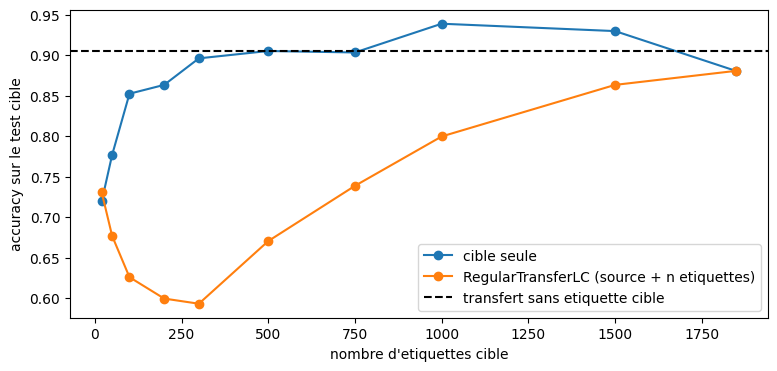

In [15]:
from sklearn.metrics import accuracy_score
from adapt.parameter_based import RegularTransferLC

modele_source_har = default_model("classification").fit(Xs9_train, ys9_train)
perm = np.random.default_rng(0).permutation(len(Xt_train))
Xt_m, yt_m = Xt_train[perm], yt_train[perm]

n_etiquettes = [20, 50, 100, 200, 300, 500, 750, 1000, 1500, len(Xt_m)]
acc_seule, acc_adapt = [], []
for n in n_etiquettes:
    acc_seule.append(predict("classification", Xt_m[:n], yt_m[:n], Xt_test, yt_test)["accuracy"])
    m = RegularTransferLC(modele_source_har, lambda_=1.0, random_state=0, verbose=0)
    m.fit(Xt_m[:n], yt_m[:n])
    acc_adapt.append(accuracy_score(yt_test, m.predict(Xt_test)))

for n, a, b in zip(n_etiquettes, acc_seule, acc_adapt):
    print(f"  {n:5d} etiquettes cible : cible seule {a:.3f}   RegularTransferLC {b:.3f}")

plt.figure(figsize=(9, 4))
plt.plot(n_etiquettes, acc_seule, marker="o", label="cible seule")
plt.plot(n_etiquettes, acc_adapt, marker="o", label="RegularTransferLC (source + n etiquettes)")
plt.axhline(resultats["sans adaptation"], color="k", linestyle="--", label="transfert sans etiquette cible")
plt.xlabel("nombre d'etiquettes cible")
plt.ylabel("accuracy sur le test cible")
plt.legend()
plt.show()

## 8. limiter le nb de points source

    2 points cible : cible seule 0.324   avec 100 points source 0.821
    5 points cible : cible seule 0.650   avec 100 points source 0.823
   10 points cible : cible seule 0.554   avec 100 points source 0.832
   15 points cible : cible seule 0.642   avec 100 points source 0.811


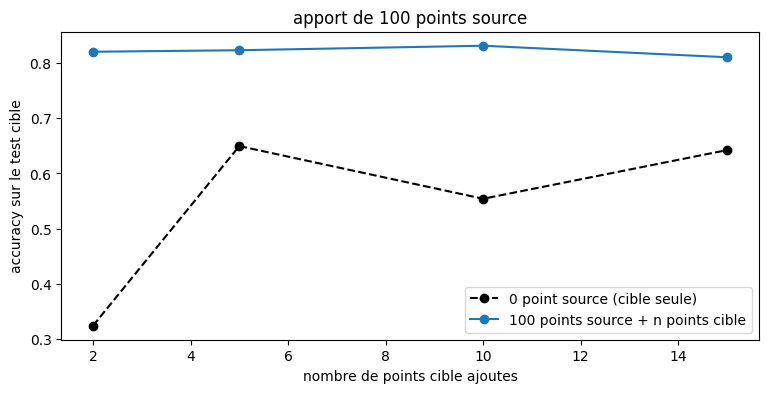

In [16]:
n_source = 100
n_petit = [2, 5, 10, 15]
perm_s = np.random.default_rng(0).permutation(len(Xs9_train))
Xs_m, ys_m = Xs9_train[perm_s][:n_source], ys9_train[perm_s][:n_source]

ns_ref, acc_ref = courbe_apprentissage(Xt_train, yt_train, Xt_test, yt_test, "classification", n_petit)
ns_b, acc_b = courbe_melange(Xs_m, ys_m, Xt_train, yt_train, Xt_test, yt_test, "classification", n_petit)

for n, a, b in zip(n_petit, acc_ref, acc_b):
    print(f"  {n:3d} points cible : cible seule {a:.3f}   avec {n_source} points source {b:.3f}")

plt.figure(figsize=(9, 4))
plt.plot(ns_ref, acc_ref, marker="o", color="k", linestyle="--", label="0 point source (cible seule)")
plt.plot(ns_b, acc_b, marker="o", label=f"{n_source} points source + n points cible")
plt.xlabel("nombre de points cible ajoutes")
plt.ylabel("accuracy sur le test cible")
plt.title(f"apport de {n_source} points source")
plt.legend()
plt.show()

## 9. matrice de confusion par classe


                    WALKING  WALKING_U  WALKING_D  SITTING  STANDING  LAYING
WALKING                 162          3          0        0         0       0
WALKING_UPSTAIRS          0        168          0        0         0       0
WALKING_DOWNSTAIRS        2         12        141        0         0       0
SITTING                   0          0          0      176        15       0
STANDING                  0          0          0        2       213       0
LAYING                    0          0          0        0         0     205

                    precision    recall  f1-score   support

           WALKING      0.988     0.982     0.985       165
  WALKING_UPSTAIRS      0.918     1.000     0.957       168
WALKING_DOWNSTAIRS      1.000     0.910     0.953       155
           SITTING      0.989     0.921     0.954       191
          STANDING      0.934     0.991     0.962       215
            LAYING      1.000     1.000     1.000       205

          accuracy                    

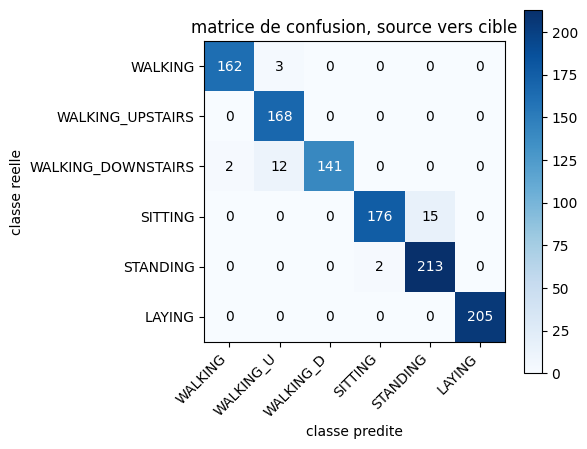

In [17]:
from sklearn.metrics import confusion_matrix, classification_report

noms_activites = [activites[str(k)] for k in range(1, 7)]
modele_cm = default_model("classification").fit(Xs_train, ys_train)
pred_cm = modele_cm.predict(Xt_test)
cm = confusion_matrix(yt_test, pred_cm, labels=range(1, 7))

print(pd.DataFrame(cm, index=noms_activites, columns=[n[:9] for n in noms_activites]).to_string())
print()
print(classification_report(yt_test, pred_cm, labels=range(1, 7), target_names=noms_activites, digits=3))

mobiles = [1, 2, 3]
groupe_vrai = np.isin(yt_test, mobiles)
groupe_pred = np.isin(pred_cm, mobiles)
print("erreurs entre groupes mobile et immobile :", int((groupe_vrai != groupe_pred).sum()), "sur", len(yt_test))
print("erreurs totales                          :", int((yt_test != pred_cm).sum()))

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
for a in range(6):
    for b in range(6):
        plt.text(b, a, cm[a, b], ha="center", va="center",
                 color="white" if cm[a, b] > cm.max() / 2 else "black")
plt.xticks(range(6), [n[:9] for n in noms_activites], rotation=45, ha="right")
plt.yticks(range(6), noms_activites)
plt.xlabel("classe predite")
plt.ylabel("classe reelle")
plt.title("matrice de confusion, source vers cible")
plt.colorbar()
plt.tight_layout()
plt.show()

## 10. validation croisee par sujet

GroupKFold(5) sur la source : 0.926 en moyenne, de 0.866 a 0.968
LeaveOneGroupOut sur la source : 0.931 en moyenne, de 0.768 a 0.994
  sujets les plus difficiles : [14, 16, 6]
transfert sujet par sujet sur la cible : {np.int64(2): 0.964, np.int64(4): 0.959, np.int64(9): 0.882, np.int64(10): 0.837, np.int64(12): 0.953, np.int64(13): 0.976, np.int64(18): 0.953, np.int64(20): 0.958, np.int64(24): 0.995}


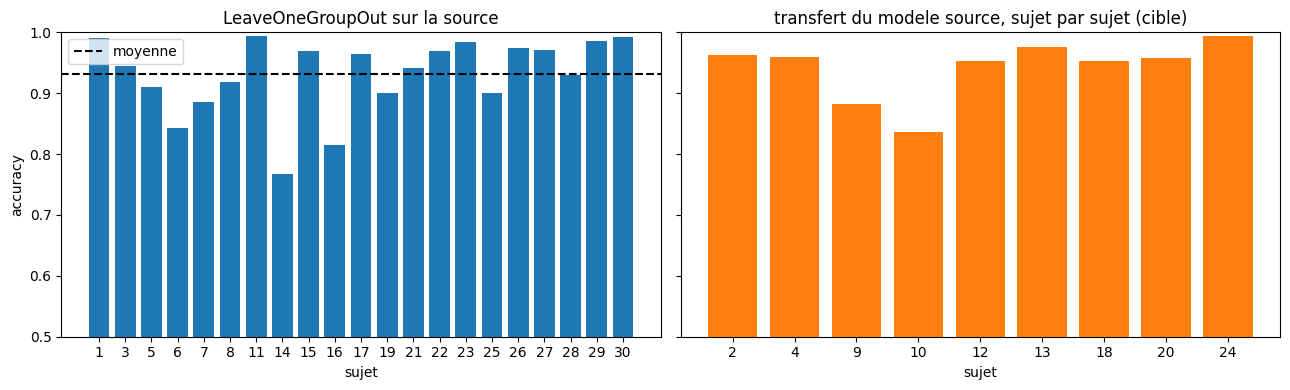

In [18]:
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut

scores_gkf = [predict("classification", Xs[tr], ys[tr], Xs[te], ys[te])["accuracy"]
              for tr, te in GroupKFold(n_splits=5).split(Xs, ys, groups=subj_s)]
print(f"GroupKFold(5) sur la source : {np.mean(scores_gkf):.3f} en moyenne, "
      f"de {min(scores_gkf):.3f} a {max(scores_gkf):.3f}")

scores_logo, sujets_logo = [], []
for tr, te in LeaveOneGroupOut().split(Xs, ys, groups=subj_s):
    scores_logo.append(predict("classification", Xs[tr], ys[tr], Xs[te], ys[te])["accuracy"])
    sujets_logo.append(int(subj_s[te][0]))
print(f"LeaveOneGroupOut sur la source : {np.mean(scores_logo):.3f} en moyenne, "
      f"de {min(scores_logo):.3f} a {max(scores_logo):.3f}")
print("  sujets les plus difficiles :",
      [s for _, s in sorted(zip(scores_logo, sujets_logo))[:3]])

modele_cv = default_model("classification").fit(Xs_train, ys_train)
sujets_cible = sorted(set(subj_t))
scores_cible = [float((modele_cv.predict(Xt[subj_t == s]) == yt[subj_t == s]).mean())
                for s in sujets_cible]
print("transfert sujet par sujet sur la cible :",
      {s: round(a, 3) for s, a in zip(sujets_cible, scores_cible)})

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
axes[0].bar([str(s) for s in sujets_logo], scores_logo)
axes[0].axhline(np.mean(scores_logo), color="k", linestyle="--", label="moyenne")
axes[0].set_title("LeaveOneGroupOut sur la source")
axes[0].set_xlabel("sujet")
axes[0].set_ylabel("accuracy")
axes[0].legend()
axes[1].bar([str(s) for s in sujets_cible], scores_cible, color="tab:orange")
axes[1].set_title("transfert du modele source, sujet par sujet (cible)")
axes[1].set_xlabel("sujet")
plt.ylim(0.5, 1.0)
plt.tight_layout()
plt.show()

## 11. validation croisee sur la cible

GroupKFold(3) interne a la cible : 0.860, de 0.859 a 0.861
LeaveOneGroupOut interne a la cible : 0.886, de 0.751 a 0.965


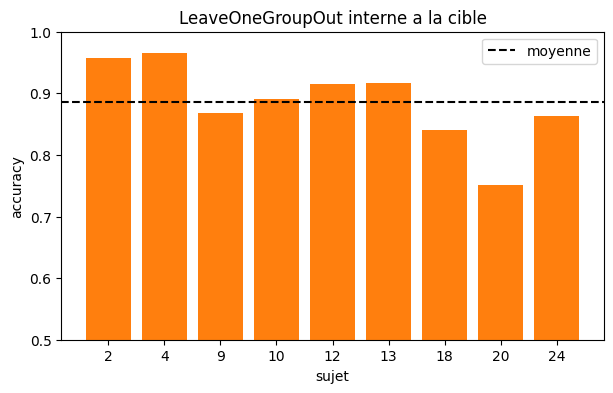

In [19]:
scores_gkf_c = [predict("classification", Xt[tr], yt[tr], Xt[te], yt[te])["accuracy"]
                for tr, te in GroupKFold(n_splits=3).split(Xt, yt, groups=subj_t)]
print(f"GroupKFold(3) interne a la cible : {np.mean(scores_gkf_c):.3f}, "
      f"de {min(scores_gkf_c):.3f} a {max(scores_gkf_c):.3f}")

scores_logo_c, sujets_logo_c = [], []
for tr, te in LeaveOneGroupOut().split(Xt, yt, groups=subj_t):
    scores_logo_c.append(predict("classification", Xt[tr], yt[tr], Xt[te], yt[te])["accuracy"])
    sujets_logo_c.append(int(subj_t[te][0]))
print(f"LeaveOneGroupOut interne a la cible : {np.mean(scores_logo_c):.3f}, "
      f"de {min(scores_logo_c):.3f} a {max(scores_logo_c):.3f}")


plt.figure(figsize=(7, 4))
plt.bar([str(s) for s in sujets_logo_c], scores_logo_c, color="tab:orange")
plt.axhline(np.mean(scores_logo_c), color="k", linestyle="--", label="moyenne")
plt.xlabel("sujet")
plt.ylabel("accuracy")
plt.title("LeaveOneGroupOut interne a la cible")
plt.ylim(0.5, 1.0)
plt.legend()
plt.show()

## 12. les sujets difficiles


sujet 14 : accuracy 0.768, 75 erreurs sur 323, 0 croisant mobile et immobile
    marche -> montee : 59
    assis -> debout : 8
    debout -> assis : 5
sujet 16 : accuracy 0.814, 68 erreurs sur 366, 0 croisant mobile et immobile
    debout -> assis : 41
    assis -> debout : 17
    montee -> descente : 7
sujet 11 : accuracy 0.994, 2 erreurs sur 316, 0 croisant mobile et immobile
    assis -> debout : 2


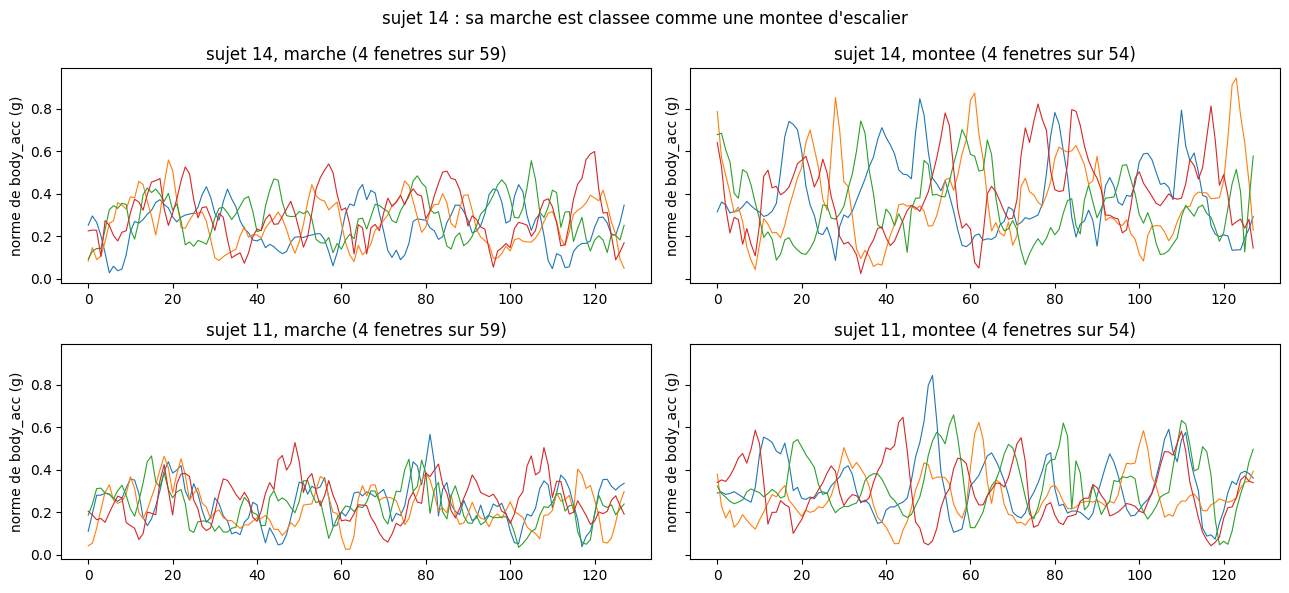

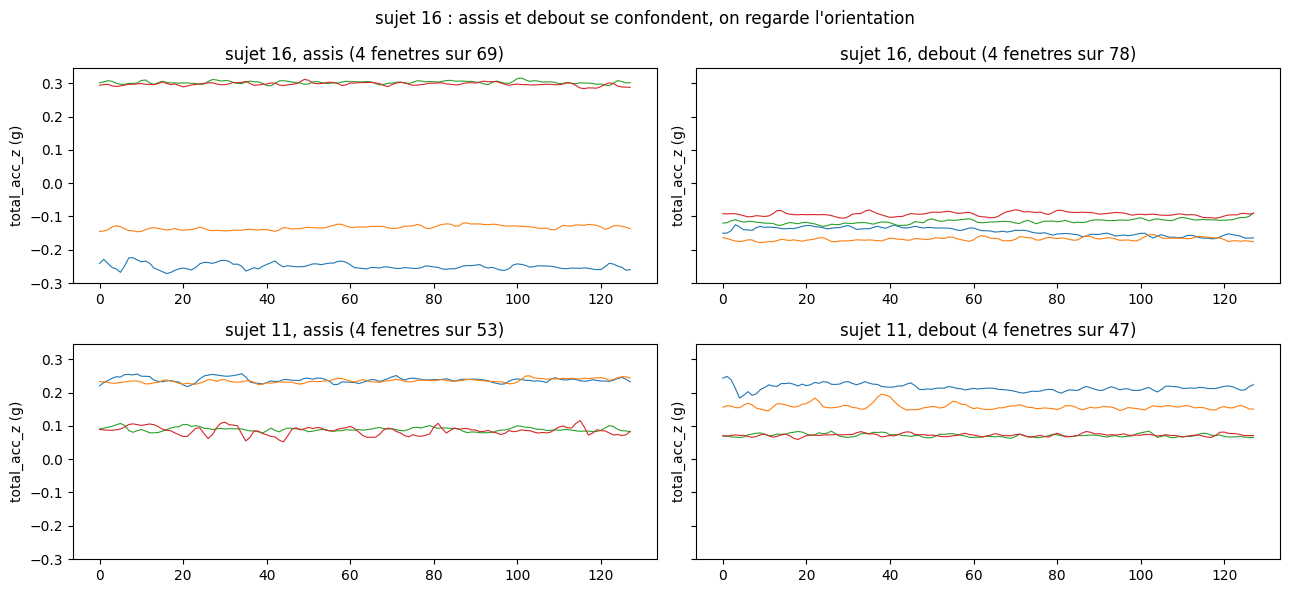

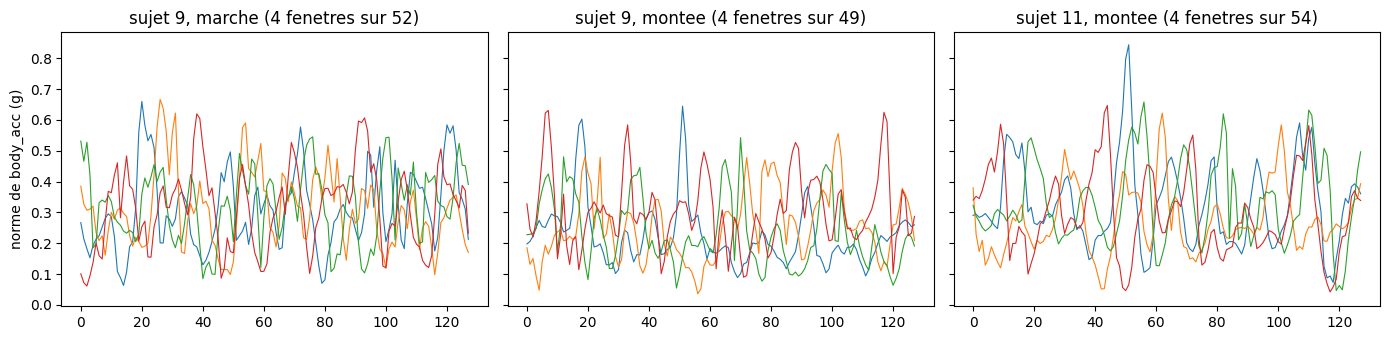


norme mesuree par sujet : de 1.014 a 1.024
  sujet 14 : 1.021   sujet 16 : 1.019


In [20]:
signaux_tr = f"{data_dir}/train/Inertial Signals"
brut = {n: np.loadtxt(f"{signaux_tr}/{n}_train.txt")
        for n in ["body_acc_x", "body_acc_y", "body_acc_z",
                  "total_acc_x", "total_acc_y", "total_acc_z"]}
sujets_src = sorted(set(subj_s))
norme_body = np.sqrt(brut["body_acc_x"] ** 2 + brut["body_acc_y"] ** 2 + brut["body_acc_z"] ** 2)

noms_act = {1: "marche", 2: "montee", 3: "descente", 4: "assis", 5: "debout", 6: "couche"}
mobiles = {1, 2, 3}

for s in [14, 16, 11]:
    m = subj_s == s
    modele = default_model("classification").fit(Xs[~m], ys[~m])
    pred = modele.predict(Xs[m])
    erreurs = [(int(a), int(b)) for a, b in zip(ys[m], pred) if a != b]
    croisees = sum(1 for a, b in erreurs if (a in mobiles) != (b in mobiles))
    print(f"sujet {s} : accuracy {(pred == ys[m]).mean():.3f}, {len(erreurs)} erreurs sur {len(pred)}, "
          f"{croisees} croisant mobile et immobile")
    for (a, b), k in Counter(erreurs).most_common(3):
        print(f"    {noms_act[a]} -> {noms_act[b]} : {k}")

def trace(ax, sujet, activite, signal, groupe=None, etiquettes=None, n=4):
    g = subj_s if groupe is None else groupe
    y = ys if etiquettes is None else etiquettes
    idx = np.where((g == sujet) & (y == activite))[0]
    for i in idx[::max(1, len(idx) // n)][:n]:
        ax.plot(signal[i], linewidth=0.8)
    ax.set_title(f"sujet {sujet}, {noms_act[activite]} ({n} fenetres sur {len(idx)})")

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharey=True)
for col, act in enumerate([1, 2]):
    for lig, sujet in enumerate([14, 11]):
        trace(axes[lig][col], sujet, act, norme_body)
        axes[lig][col].set_ylabel("norme de body_acc (g)")
plt.suptitle("sujet 14 : sa marche est classee comme une montee d'escalier")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharey=True)
for col, act in enumerate([4, 5]):
    for lig, sujet in enumerate([16, 11]):
        trace(axes[lig][col], sujet, act, brut["total_acc_z"])
        axes[lig][col].set_ylabel("total_acc_z (g)")
plt.suptitle("sujet 16 : assis et debout se confondent, on regarde l'orientation")
plt.tight_layout()
plt.show()

brut_te = {n: np.loadtxt(f"{data_dir}/test/Inertial Signals/{n}_test.txt")
           for n in ["body_acc_x", "body_acc_y", "body_acc_z"]}
norme_body_te = np.sqrt(brut_te["body_acc_x"] ** 2 + brut_te["body_acc_y"] ** 2 + brut_te["body_acc_z"] ** 2)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, act in zip(axes, [1, 2]):
    trace(ax, 9, act, norme_body_te, groupe=subj_t, etiquettes=yt)
trace(axes[2], 11, 2, norme_body)
axes[0].set_ylabel("norme de body_acc (g)")
plt.tight_layout()
plt.show()

statiques = np.isin(ys, [4, 5, 6])
grav = {a: brut[f"total_acc_{a}"].mean(axis=1) for a in "xyz"}
norme_grav = [float(np.sqrt(grav["x"][m] ** 2 + grav["y"][m] ** 2 + grav["z"][m] ** 2).mean())
              for m in [(subj_s == s) & statiques for s in sujets_src]]
print()
print(f"norme mesuree par sujet : de {min(norme_grav):.3f} a {max(norme_grav):.3f}")
print(f"  sujet 14 : {norme_grav[sujets_src.index(14)]:.3f}   sujet 16 : {norme_grav[sujets_src.index(16)]:.3f}")

## 13. un mauvais sujet en source

                     source  fenetres  accuracy cible
              les 21 sujets      7352           0.958
   19 sujets, sans 14 et 16      6663           0.934
         2 pires : 14 et 16       689           0.745
     2 meilleurs : 11 et 30       699           0.761
     4 pires : 14, 16, 6, 7      1322           0.869
4 meilleurs : 11, 30, 1, 29      1390           0.841

retirer 2 sujets au hasard : 0.952 en moyenne, de 0.938 a 0.961
retirer 14 et 16           : 0.934
tirages faisant moins bien : 0 sur 15


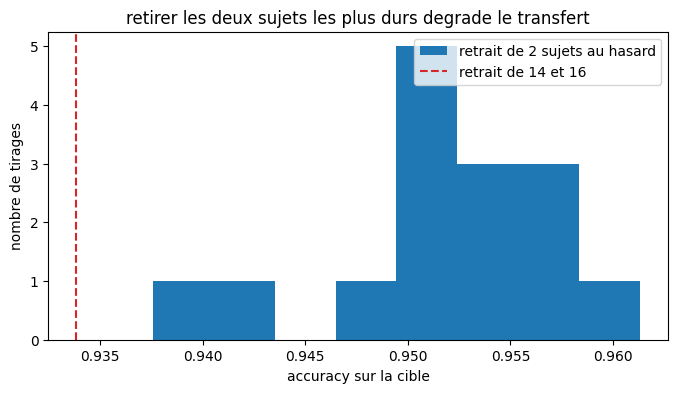

In [21]:
def accuracy_source(sujets):
    m = np.isin(subj_s, sujets)
    return predict("classification", Xs[m], ys[m], Xt, yt)["accuracy"], int(m.sum())

compositions = [("les 21 sujets", sujets_src),
                ("19 sujets, sans 14 et 16", [s for s in sujets_src if s not in (14, 16)]),
                ("2 pires : 14 et 16", [14, 16]),
                ("2 meilleurs : 11 et 30", [11, 30]),
                ("4 pires : 14, 16, 6, 7", [14, 16, 6, 7]),
                ("4 meilleurs : 11, 30, 1, 29", [11, 30, 1, 29])]

lignes_src = []
for nom, suj in compositions:
    a, n = accuracy_source(suj)
    lignes_src.append([nom, n, round(a, 3)])
print(pd.DataFrame(lignes_src, columns=["source", "fenetres", "accuracy cible"]).to_string(index=False))

rng_src = np.random.default_rng(0)
tirages = []
for _ in range(15):
    exclus = rng_src.choice(sujets_src, 2, replace=False)
    tirages.append(accuracy_source([s for s in sujets_src if s not in exclus])[0])
sans_pires = accuracy_source([s for s in sujets_src if s not in (14, 16)])[0]
print()
print(f"retirer 2 sujets au hasard : {np.mean(tirages):.3f} en moyenne, "
      f"de {min(tirages):.3f} a {max(tirages):.3f}")
print(f"retirer 14 et 16           : {sans_pires:.3f}")
print(f"tirages faisant moins bien : {sum(1 for t in tirages if t < sans_pires)} sur 15")

plt.figure(figsize=(8, 4))
plt.hist(tirages, bins=8, label="retrait de 2 sujets au hasard")
plt.axvline(sans_pires, color="tab:red", linestyle="--", label="retrait de 14 et 16")
plt.xlabel("accuracy sur la cible")
plt.ylabel("nombre de tirages")
plt.title("retirer les deux sujets les plus durs degrade le transfert")
plt.legend()
plt.show()

## 14. scores locaux

accuracy globale sur la cible : 0.958

rappel par classe, toutes cibles confondues
  marche     0.986   (496 fenetres)
  montee     0.943   (471 fenetres)
  descente   0.969   (420 fenetres)
  assis      0.888   (491 fenetres)
  debout     0.959   (532 fenetres)
  couche     0.998   (537 fenetres)

rappel par sujet et par classe
    marche  montee  descente  assis  debout  couche  global
2     1.00    1.00      0.98   0.91    0.98    1.00   0.980
4     1.00    0.96      1.00   0.84    0.89    1.00   0.950
9     1.00    0.65      1.00   0.68    0.93    1.00   0.875
10    0.94    0.83      1.00   0.85    0.84    1.00   0.912
12    1.00    1.00      0.98   0.84    0.98    1.00   0.969
13    1.00    1.00      0.96   1.00    1.00    1.00   0.994
18    1.00    1.00      0.87   0.96    1.00    0.98   0.973
20    0.94    1.00      0.96   0.86    1.00    1.00   0.960
24    0.98    1.00      1.00   1.00    0.94    1.00   0.987

les cinq cases les plus basses
  sujet  9  montee     0.65
  sujet  

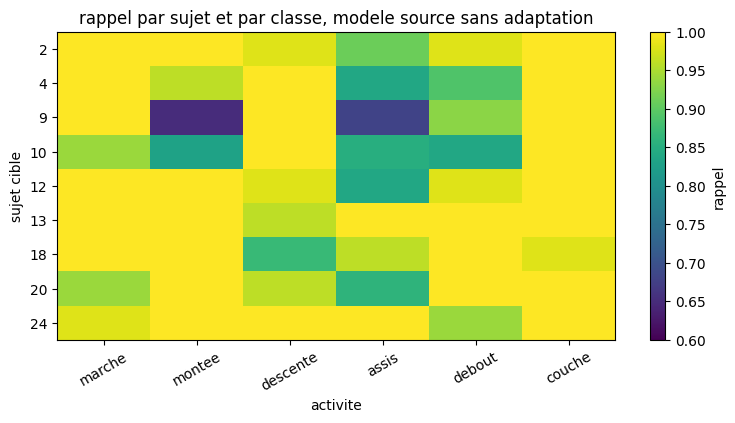

In [22]:
activites = {1: "marche", 2: "montee", 3: "descente", 4: "assis", 5: "debout", 6: "couche"}

modele_source = default_model("classification").fit(Xs, ys)
pred_cible = modele_source.predict(Xt)
print("accuracy globale sur la cible :", round(float((pred_cible == yt).mean()), 3))

print()
print("rappel par classe, toutes cibles confondues")
for a in range(1, 7):
    m = yt == a
    print(f"  {activites[a]:10s} {float((pred_cible[m] == a).mean()):.3f}   ({int(m.sum())} fenetres)")

sujets_cible = sorted(set(subj_t))
table_classe = pd.DataFrame(index=sujets_cible, columns=[activites[a] for a in range(1, 7)], dtype=float)
for s in sujets_cible:
    for a in range(1, 7):
        m = (subj_t == s) & (yt == a)
        table_classe.loc[s, activites[a]] = round(float((pred_cible[m] == a).mean()), 2)
table_classe["global"] = [round(float((pred_cible[subj_t == s] == yt[subj_t == s]).mean()), 3)
                          for s in sujets_cible]
print()
print("rappel par sujet et par classe")
print(table_classe.to_string())

cases = sorted((table_classe.loc[s, c], s, c) for s in sujets_cible for c in table_classe.columns[:-1])
print()
print("les cinq cases les plus basses")
for v, s, c in cases[:5]:
    print(f"  sujet {s:2d}  {c:10s} {v:.2f}")

plt.figure(figsize=(9, 4))
plt.imshow(table_classe.iloc[:, :-1].to_numpy(), aspect="auto", vmin=0.6, vmax=1.0)
plt.colorbar(label="rappel")
plt.xticks(range(6), [activites[a] for a in range(1, 7)], rotation=30)
plt.yticks(range(len(sujets_cible)), sujets_cible)
plt.xlabel("activite")
plt.ylabel("sujet cible")
plt.title("rappel par sujet et par classe, modele source sans adaptation")
plt.show()

## 15. adaptation a partir de tres peu de donnees

source forte (21 sujets) : 3 fenetres pour 2 activites, moyenne sur 3 tirages
 sujet  sans adaptation  lambda=0.01  lambda=0.1  lambda=0.5  lambda=1  lambda=10  lambda=100  lambda=1000
     2            0.980        0.755       0.755       0.756     0.758      0.856       0.980        0.980
     4            0.950        0.661       0.662       0.666     0.670      0.838       0.955        0.950
     9            0.874        0.700       0.700       0.701     0.704      0.807       0.865        0.874
    10            0.912        0.701       0.701       0.704     0.708      0.809       0.919        0.912
    12            0.968        0.695       0.695       0.695     0.701      0.790       0.959        0.968
    13            0.994        0.726       0.726       0.728     0.731      0.890       0.994        0.994
    18            0.973        0.785       0.785       0.786     0.794      0.876       0.972        0.973
    20            0.963        0.737       0.737       0.737     0

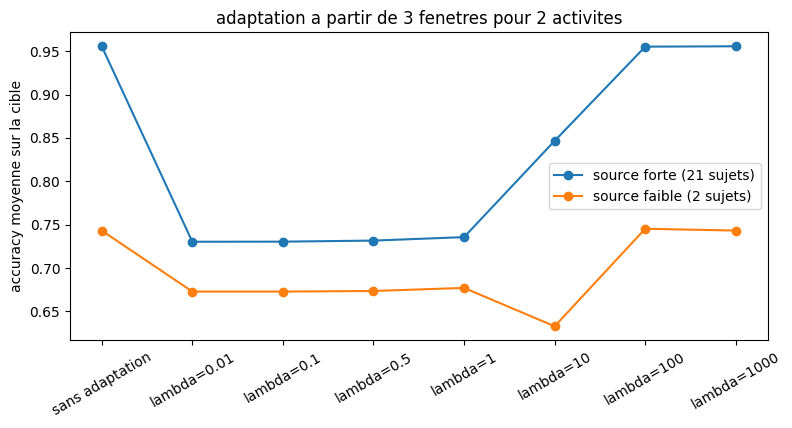

In [23]:
from adapt.parameter_based import RegularTransferLC
import io, contextlib

source_forte = default_model("classification").fit(Xs, ys)
masque_faible = np.isin(subj_s, [14, 16])
source_faible = default_model("classification").fit(Xs[masque_faible], ys[masque_faible])

lambdas = [0.01, 0.1, 0.5, 1.0, 10.0, 100.0, 1000.0]
activites_connues = [1, 4]
n_fenetres = 3
n_tirages = 3

def adapter(source, sujet, graine):
    rng = np.random.default_rng(graine)
    m = subj_t == sujet
    X_all, y_all = Xt[m], yt[m]
    idx = []
    for a in activites_connues:
        k = np.where(y_all == a)[0]
        idx += list(rng.permutation(k)[:n_fenetres])
    idx = np.array(idx)
    reste = np.setdiff1d(np.arange(len(y_all)), idx)
    Xa, ya = X_all[idx], y_all[idx]
    Xe, ye = X_all[reste], y_all[reste]
    ligne = [float((source.predict(Xe) == ye).mean())]
    for lam in lambdas:
        r = RegularTransferLC(source, lambda_=lam, random_state=0, verbose=0)
        with contextlib.redirect_stdout(io.StringIO()):
            r.fit(Xa, ya)
        ligne.append(float((r.predict(Xe) == ye).mean()))
    return ligne

resume = {}
for nom, source in [("source forte (21 sujets)", source_forte), ("source faible (2 sujets)", source_faible)]:
    lignes = []
    for s in sujets_cible:
        tirages = [adapter(source, s, g) for g in range(n_tirages)]
        lignes.append([s] + list(np.mean(tirages, axis=0).round(3)))
    tab = pd.DataFrame(lignes, columns=["sujet", "sans adaptation"] + [f"lambda={l:g}" for l in lambdas])
    print(nom, f": {n_fenetres} fenetres pour {len(activites_connues)} activites, moyenne sur {n_tirages} tirages")
    print(tab.to_string(index=False))
    resume[nom] = tab.iloc[:, 1:].mean()
    print("  moyenne sur les 9 sujets :", resume[nom].round(3).to_dict())
    print()

pos = np.arange(len(lambdas) + 1)
plt.figure(figsize=(9, 4))
for nom, v in resume.items():
    plt.plot(pos, v.to_numpy(), marker="o", label=nom)
plt.xticks(pos, ["sans adaptation"] + [f"lambda={l:g}" for l in lambdas], rotation=30)
plt.ylabel("accuracy moyenne sur la cible")
plt.title(f"adaptation a partir de {n_fenetres} fenetres pour {len(activites_connues)} activites")
plt.legend()
plt.show()

## 16. structure des enregistrements

deux fenetres qui se suivent dans le temps partagent 64 de leurs 128 mesures. comparer la seconde moitie d'une fenetre a la premiere moitie de la suivante permet donc de savoir si elles sont contigues, et de decouper le fichier en troncons d'enregistrement continu.

In [24]:
noms_act = {1: "marche", 2: "montee", 3: "descente", 4: "assis", 5: "debout", 6: "couche"}

y_tout = np.concatenate([ys, yt])
s_tout = np.concatenate([subj_s, subj_t])
n_train = len(ys)

def charger(nom):
    return np.vstack([np.loadtxt(f"{data_dir}/train/Inertial Signals/{nom}_train.txt"),
                      np.loadtxt(f"{data_dir}/test/Inertial Signals/{nom}_test.txt")])

acc_x = charger("total_acc_x")
continu = np.array([False if i == n_train - 1 else np.allclose(acc_x[i, 64:], acc_x[i + 1, :64], atol=1e-6)
                    for i in range(len(acc_x) - 1)])
vrais = np.ones(len(continu), dtype=bool)
vrais[n_train - 1] = False
print(f"{int(vrais.sum())} couples de lignes voisines, hors jonction entre les 2 fichiers")
print(f"  {int(continu[vrais].sum())} contigus dans le temps")
print(f"  {int((~continu[vrais]).sum())} coupures, soit une jonction sur "
      f"{round(vrais.sum() / (~continu[vrais]).sum())}")

def blocs_du_sujet(su):
    idx = np.where(s_tout == su)[0]
    d = idx[0]
    for k in range(1, len(idx) + 1):
        if k == len(idx) or y_tout[idx[k]] != y_tout[idx[k - 1]]:
            f = idx[k - 1]
            bornes = [d] + [j + 1 for j in range(d, f) if not continu[j]]
            yield noms_act[y_tout[d]], [(bornes[r], bornes[r + 1] - 1 if r + 1 < len(bornes) else f)
                                        for r in range(len(bornes))]
            if k < len(idx): d = idx[k]

nb_blocs = {a: [] for a in noms_act.values()}
nb_tron = {a: [] for a in noms_act.values()}
for su in sorted(set(s_tout)):
    compte = {a: 0 for a in noms_act.values()}
    for a, segs in blocs_du_sujet(su):
        nb_tron[a].append(len(segs))
        compte[a] += 1
    for a, nb in compte.items():
        if nb:
            nb_blocs[a].append(nb)

total_blocs = sum(len(v) for v in nb_tron.values())
total_tron = sum(sum(v) for v in nb_tron.values())
print(f"  {total_tron} troncons repartis sur {total_blocs} blocs d'activite")

lignes_struct = [[a, round(float(np.mean(nb_blocs[a])), 1), round(float(np.mean(nb_tron[a])), 1)]
                 for a in ["debout", "assis", "couche", "marche", "montee", "descente"]]
print()
print(pd.DataFrame(lignes_struct, columns=["activite", "blocs par sujet (moyenne)",
                                           "troncons par bloc (moyenne)"]).to_string(index=False))


10297 couples de lignes voisines, hors jonction entre les 2 fichiers
  9442 contigus dans le temps
  855 coupures, soit une jonction sur 12
  857 troncons repartis sur 400 blocs d'activite

activite  blocs par sujet (moyenne)  troncons par bloc (moyenne)
  debout                        2.0                          2.0
   assis                        2.0                          2.0
  couche                        2.0                          2.0
  marche                        2.0                          2.1
  montee                        2.6                          2.4
descente                        2.7                          2.3


## 17. adapt au niveau local


In [25]:
from sklearn.model_selection import LeaveOneGroupOut
from adapt.feature_based import CORAL
from adapt.instance_based import KMM

methodes = ["sans adaptation", "CORAL", "KMM", "RegularTransferLC", "cible -> cible"]
pred_tous = {m: {} for m in methodes}
rng_local = np.random.default_rng(0)

for k in range(5):
    tirage_src = list(rng_local.permutation(sorted(set(subj_s)))[:6])
    Xa, ya = Xs[np.isin(subj_s, tirage_src)], ys[np.isin(subj_s, tirage_src)]
    source = default_model("classification").fit(Xa, ya)
    pred = {m: np.empty(len(yt), dtype=int) for m in methodes}
    for tr, te in LeaveOneGroupOut().split(Xt, yt, subj_t):
        Xtr, ytr, Xte = Xt[tr], yt[tr], Xt[te]
        pred["sans adaptation"][te] = source.predict(Xte)
        with contextlib.redirect_stdout(io.StringIO()):
            pred["CORAL"][te] = CORAL(default_model("classification"), Xt=Xtr,
                                      random_state=0, verbose=0).fit(Xa, ya).predict(Xte)
            pred["KMM"][te] = KMM(default_model("classification"), Xt=Xtr, random_state=0,
                                  verbose=0, max_size=1000).fit(Xa, ya).predict(Xte)
            pred["RegularTransferLC"][te] = RegularTransferLC(source, lambda_=1.0, random_state=0,
                                                              verbose=0).fit(Xtr, ytr).predict(Xte)
        pred["cible -> cible"][te] = default_model("classification").fit(Xtr, ytr).predict(Xte)
    for m in methodes:
        pred_tous[m][k] = pred[m]

lignes_global = []
for m in methodes:
    v = np.concatenate([pred_tous[m][k] for k in range(5)])
    y_tous = np.tile(yt, 5)
    lignes_global.append([m, round(float((v == y_tous).mean()), 3)]
                         + [round(float((v[y_tous == a] == a).mean()), 3) for a in sorted(noms_act)])
print("rappel par classe, tous sujets confondus")
print(pd.DataFrame(lignes_global,
                   columns=["methode", "global"] + [noms_act[a] for a in sorted(noms_act)]).to_string(index=False))
print()
print()

for s_cible in sorted(set(subj_t)):
    m_suj = subj_t == s_cible
    lignes_suj = []
    for m in methodes:
        v = np.concatenate([pred_tous[m][k][m_suj] for k in range(5)])
        y_suj = np.tile(yt[m_suj], 5)
        lignes_suj.append([m, round(float((v == y_suj).mean()), 3)]
                          + [round(float((v[y_suj == a] == a).mean()), 3) if (y_suj == a).any() else np.nan
                             for a in sorted(noms_act)])
    print(f"sujet {s_cible}")
    print(pd.DataFrame(lignes_suj,
                       columns=["methode", "global"] + [noms_act[a] for a in sorted(noms_act)]).to_string(index=False))
    print()


rappel par classe, tous sujets confondus
          methode  global  marche  montee  descente  assis  debout  couche
  sans adaptation   0.899   0.918   0.832     0.858  0.896   0.902   0.975
            CORAL   0.564   0.388   0.285     0.361  0.420   0.953   0.877
              KMM   0.883   0.956   0.819     0.808  0.813   0.886   0.992
RegularTransferLC   0.938   0.950   0.969     0.948  0.892   0.926   0.948
   cible -> cible   0.883   0.869   0.845     0.764  0.890   0.902   0.994


sujet 2
          methode  global  marche  montee  descente  assis  debout  couche
  sans adaptation   0.965   0.990   0.963     1.000  0.826   0.996   1.000
            CORAL   0.571   0.325   0.421     0.468  0.235   1.000   0.963
              KMM   0.930   0.993   0.929     0.979  0.678   0.974   1.000
RegularTransferLC   0.974   1.000   1.000     0.966  0.939   0.937   0.996
   cible -> cible   0.957   1.000   0.938     0.979  0.870   0.944   1.000

sujet 4
          methode  global  marche  monte

## 18. CORAL centré

In [26]:
variantes = ["CORAL brut", "CORAL centre"]
pred_coral = {m: {} for m in variantes}
rng_coral = np.random.default_rng(0)

for k in range(5):
    tirage_src = list(rng_coral.permutation(sorted(set(subj_s)))[:6])
    Xa, ya = Xs[np.isin(subj_s, tirage_src)], ys[np.isin(subj_s, tirage_src)]
    p_var = {m: np.empty(len(yt), dtype=int) for m in variantes}
    for tr, te in LeaveOneGroupOut().split(Xt, yt, subj_t):
        Xtr, Xte = Xt[tr], Xt[te]
        with contextlib.redirect_stdout(io.StringIO()):
            p_var["CORAL brut"][te] = CORAL(default_model("classification"), Xt=Xtr,
                                            random_state=0, verbose=0).fit(Xa, ya).predict(Xte)
            mu_s, mu_t = Xa.mean(axis=0), Xtr.mean(axis=0)
            p_var["CORAL centre"][te] = CORAL(default_model("classification"), Xt=Xtr - mu_t,
                                              random_state=0, verbose=0).fit(Xa - mu_s, ya).predict(Xte - mu_t)
    for m in variantes:
        pred_coral[m][k] = p_var[m]

lignes_coral = []
for m in variantes:
    v = np.concatenate([pred_coral[m][k] for k in range(5)])
    y_tous = np.tile(yt, 5)
    lignes_coral.append([m, round(float((v == y_tous).mean()), 3)]
                        + [round(float((v[y_tous == a] == a).mean()), 3) for a in sorted(noms_act)])
print("rappel par classe, tous sujets confondus")
print(pd.DataFrame(lignes_coral,
                   columns=["variante", "global"] + [noms_act[a] for a in sorted(noms_act)]).to_string(index=False))
print()
print()

for s_cible in sorted(set(subj_t)):
    m_suj = subj_t == s_cible
    lignes_suj = []
    for m in variantes:
        v = np.concatenate([pred_coral[m][k][m_suj] for k in range(5)])
        y_suj = np.tile(yt[m_suj], 5)
        lignes_suj.append([m, round(float((v == y_suj).mean()), 3)]
                          + [round(float((v[y_suj == a] == a).mean()), 3) if (y_suj == a).any() else np.nan
                             for a in sorted(noms_act)])
    print(f"sujet {s_cible}")
    print(pd.DataFrame(lignes_suj,
                       columns=["variante", "global"] + [noms_act[a] for a in sorted(noms_act)]).to_string(index=False))
    print()

rappel par classe, tous sujets confondus
    variante  global  marche  montee  descente  assis  debout  couche
  CORAL brut   0.564   0.388   0.285     0.361  0.420   0.953   0.877
CORAL centre   0.897   0.887   0.890     0.855  0.872   0.882   0.984


sujet 2
    variante  global  marche  montee  descente  assis  debout  couche
  CORAL brut   0.571   0.325   0.421     0.468  0.235   1.000   0.963
CORAL centre   0.936   0.908   1.000     0.945  0.787   0.974   0.996

sujet 4
    variante  global  marche  montee  descente  assis  debout  couche
  CORAL brut   0.523    0.18   0.231     0.258  0.628   0.946   0.870
CORAL centre   0.920    1.00   0.950     0.960  0.920   0.711   0.985

sujet 9
    variante  global  marche  montee  descente  assis  debout  couche
  CORAL brut   0.531   0.338   0.245     0.619  0.264   0.924   0.852
CORAL centre   0.842   0.988   0.690     1.000  0.816   0.547   1.000

sujet 10
    variante  global  marche  montee  descente  assis  debout  couche
  CORAL bru